# 05. Robustness & Product Recommendation

## Цель

Проверить, насколько основной вывод устойчив к альтернативным представлениям данных, и сформулировать рекомендацию команде платежей.


## 1. Загрузка витрин

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display

ROOT_CANDIDATES=[Path.cwd().resolve(),Path.cwd().resolve().parent]
PROJECT_ROOT=next((p for p in ROOT_CANDIDATES if (p/'data/processed/users_mart.csv').exists()),None)
if PROJECT_ROOT is None: raise FileNotFoundError('Сначала выполните 01_data_audit.ipynb.')
users=pd.read_csv(PROJECT_ROOT/'data/processed/users_mart.csv')
attempts=pd.read_csv(PROJECT_ROOT/'data/processed/payment_attempts_mart.csv')
for c in ['opened_any','success_any']:
    users[c]=users[c].astype(str).str.lower().map({'true':True,'false':False}).fillna(False).astype(bool)
for c in ['opened','success','group_mismatch']:
    attempts[c]=attempts[c].astype(str).str.lower().map({'true':True,'false':False}).fillna(False).astype(bool)
users=users[users.assigned_group.isin(['A','B'])].copy()
attempts=attempts[attempts.assigned_group.isin(['A','B'])].copy()
print('Users:',users.shape,'Attempts:',attempts.shape)

Users: (1503, 18) Attempts: (2660, 23)


## 2. Сопоставление трёх представлений метрики

- **User-level primary:** успешные пользователи / пользователи, открывшие форму.
- **ITT:** успешные пользователи / все назначенные пользователи.
- **Attempt-level descriptive:** успешные попытки / открытые попытки.


In [2]:
rows=[]
for g in ['A','B']:
    u=users[users.assigned_group==g]
    a=attempts[attempts.assigned_group==g]
    opened_u=int(u.opened_any.sum()); success_u=int(u.success_any.sum())
    assigned=len(u)
    opened_a=int(a.opened.sum()); success_a=int(a.success.sum())
    rows.append({'group':g,'assigned_users':assigned,'opened_users':opened_u,'successful_users':success_u,
                 'user_CR_open_to_success':success_u/opened_u,
                 'user_ITT':success_u/assigned,
                 'opened_attempts':opened_a,'successful_attempts':success_a,
                 'attempt_CR':success_a/opened_a})
comparison=pd.DataFrame(rows).set_index('group').reindex(['A','B'])
display(comparison.style.format({c:'{:.2%}' for c in ['user_CR_open_to_success','user_ITT','attempt_CR']}))

,assigned_users,opened_users,successful_users,user_CR_open_to_success,user_ITT,opened_attempts,successful_attempts,attempt_CR
group,,,,,,,,
A,752,751,494,65.78%,65.69%,1309,652,49.81%
B,751,750,603,80.40%,80.29%,1351,870,64.40%


## 3. Кластерный bootstrap для конверсии попыток


,attempt_CR_A,attempt_CR_B,difference_B_minus_A,cluster_bootstrap_ci_low,cluster_bootstrap_ci_high,bootstrap_replicates
0,49.81%,64.40%,14.59%,10.98%,18.39%,3000


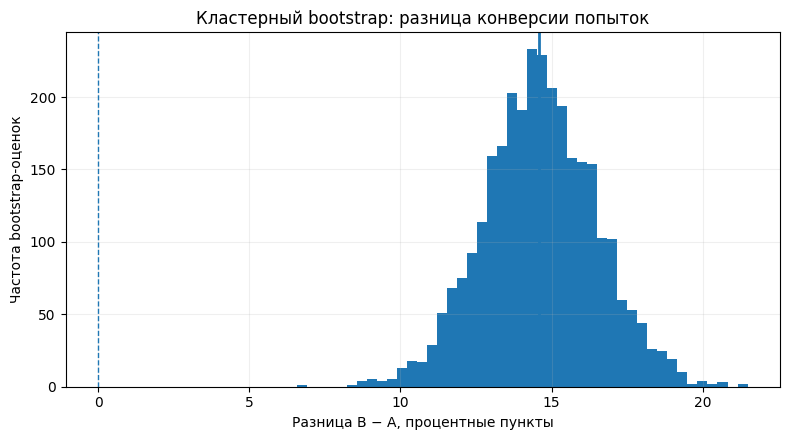

In [3]:
# Агрегируем количество открытых и успешных попыток на пользователя.
cluster_counts=(attempts.groupby(['assigned_group','user_id'])
                .agg(opened_attempts=('opened','sum'),successful_attempts=('success','sum'))
                .reset_index())
cluster_counts=cluster_counts[cluster_counts.opened_attempts>0]

rng=np.random.default_rng(202604)
N_BOOT=3000
boot_cr={'A':np.empty(N_BOOT),'B':np.empty(N_BOOT)}
for group in ['A','B']:
    g=cluster_counts[cluster_counts.assigned_group==group]
    opened_arr=g.opened_attempts.to_numpy(dtype=float)
    success_arr=g.successful_attempts.to_numpy(dtype=float)
    n=len(g)
    idx=rng.integers(0,n,size=(N_BOOT,n))
    den=opened_arr[idx].sum(axis=1)
    num=success_arr[idx].sum(axis=1)
    boot_cr[group]=num/den

boot_diff=boot_cr['B']-boot_cr['A']
observed_attempt_diff=(comparison.loc['B','attempt_CR']-comparison.loc['A','attempt_CR'])
ci=np.quantile(boot_diff,[.025,.975])
bootstrap_summary=pd.DataFrame([{
    'attempt_CR_A':comparison.loc['A','attempt_CR'],
    'attempt_CR_B':comparison.loc['B','attempt_CR'],
    'difference_B_minus_A':observed_attempt_diff,
    'cluster_bootstrap_ci_low':ci[0],
    'cluster_bootstrap_ci_high':ci[1],
    'bootstrap_replicates':N_BOOT
}])
display(bootstrap_summary.style.format({c:'{:.2%}' for c in bootstrap_summary.columns if c!='bootstrap_replicates'}))

fig,ax=plt.subplots(figsize=(8,4.5))
ax.hist(boot_diff*100,bins=45)
ax.axvline(0,linestyle='--',linewidth=1)
ax.axvline(observed_attempt_diff*100,linestyle='-',linewidth=2)
ax.set_xlabel('Разница B − A, процентные пункты')
ax.set_ylabel('Частота bootstrap-оценок')
ax.set_title('Кластерный bootstrap: разница конверсии попыток')
ax.grid(alpha=.2); plt.tight_layout(); plt.show()

## 4. Чувствительность к конфликтующей группе одной попытки

В одной записи поле group в листе «Платежи» не совпадает с группой того же клиента в листе «Пользователи». 

In [4]:
conflicts=attempts[attempts.group_mismatch].copy()
print(f'Конфликтующих попыток: {len(conflicts)}')
display(conflicts[['payment_id','user_id','payment_group_raw','assigned_group','opened','entered','confirmed','success']])

attempts_without_conflict=attempts[~attempts.group_mismatch].copy()
success_without_conflict=(attempts_without_conflict.groupby('user_id')['success'].max())

sensitivity_rows=[]
for group in ['A','B']:
    base=users[(users.assigned_group==group)&(users.opened_any)].copy()
    base['success_without_conflict']=base.user_id.map(success_without_conflict).fillna(False).astype(bool)
    sensitivity_rows.append({'group':group,'n_opened':len(base),
                             'success_main':int(base.success_any.sum()),
                             'cr_main':base.success_any.mean(),
                             'success_excl_conflict':int(base.success_without_conflict.sum()),
                             'cr_excl_conflict':base.success_without_conflict.mean()})
sensitivity=pd.DataFrame(sensitivity_rows).set_index('group').reindex(['A','B'])
display(sensitivity.style.format({'cr_main':'{:.2%}','cr_excl_conflict':'{:.2%}'}))
main_delta=sensitivity.loc['B','cr_main']-sensitivity.loc['A','cr_main']
alt_delta=sensitivity.loc['B','cr_excl_conflict']-sensitivity.loc['A','cr_excl_conflict']
print(f'Основная разница B − A: {main_delta*100:+.2f} п.п.')
print(f'После исключения конфликтующей попытки: {alt_delta*100:+.2f} п.п.')

Конфликтующих попыток: 1


,payment_id,user_id,payment_group_raw,assigned_group,opened,entered,confirmed,success
2659,99002,1010.0,B,A,True,True,True,True


,n_opened,success_main,cr_main,success_excl_conflict,cr_excl_conflict
group,,,,,
A,751,494,65.78%,493,65.65%
B,750,603,80.40%,603,80.40%


Основная разница B − A: +14.62 п.п.
После исключения конфликтующей попытки: +14.75 п.п.
